## Tải và Kiểm tra Dữ liệu

--- 5 dòng đầu tiên ---
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

--- Thông tin dữ liệu ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
None

--- Số lượng mẫu theo từng loài ---
species
setosa        50
versicolor    50
virginica     50
Name: c

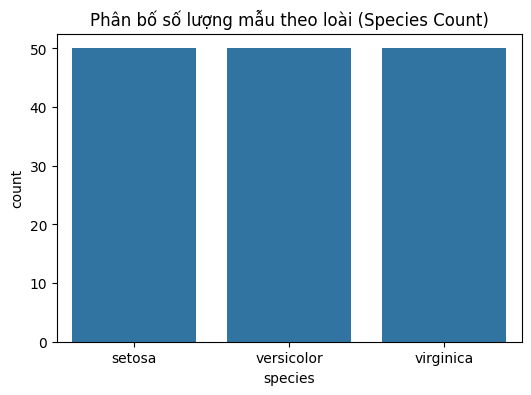

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Tải bộ dữ liệu Iris từ Seaborn
df = sns.load_dataset('iris')

# Kiểm tra 5 dòng đầu
print("--- 5 dòng đầu tiên ---")
print(df.head())

# Kiểm tra thông tin tổng quan
print("\n--- Thông tin dữ liệu ---")
print(df.info())

# Kiểm tra sự cân bằng của biến mục tiêu (Species)
print("\n--- Số lượng mẫu theo từng loài ---")
print(df['species'].value_counts())

# Trực quan hóa sự cân bằng
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='species')
plt.title('Phân bố số lượng mẫu theo loài (Species Count)')
plt.show()

## Histogram và Box Plot cho từng đặc trưng

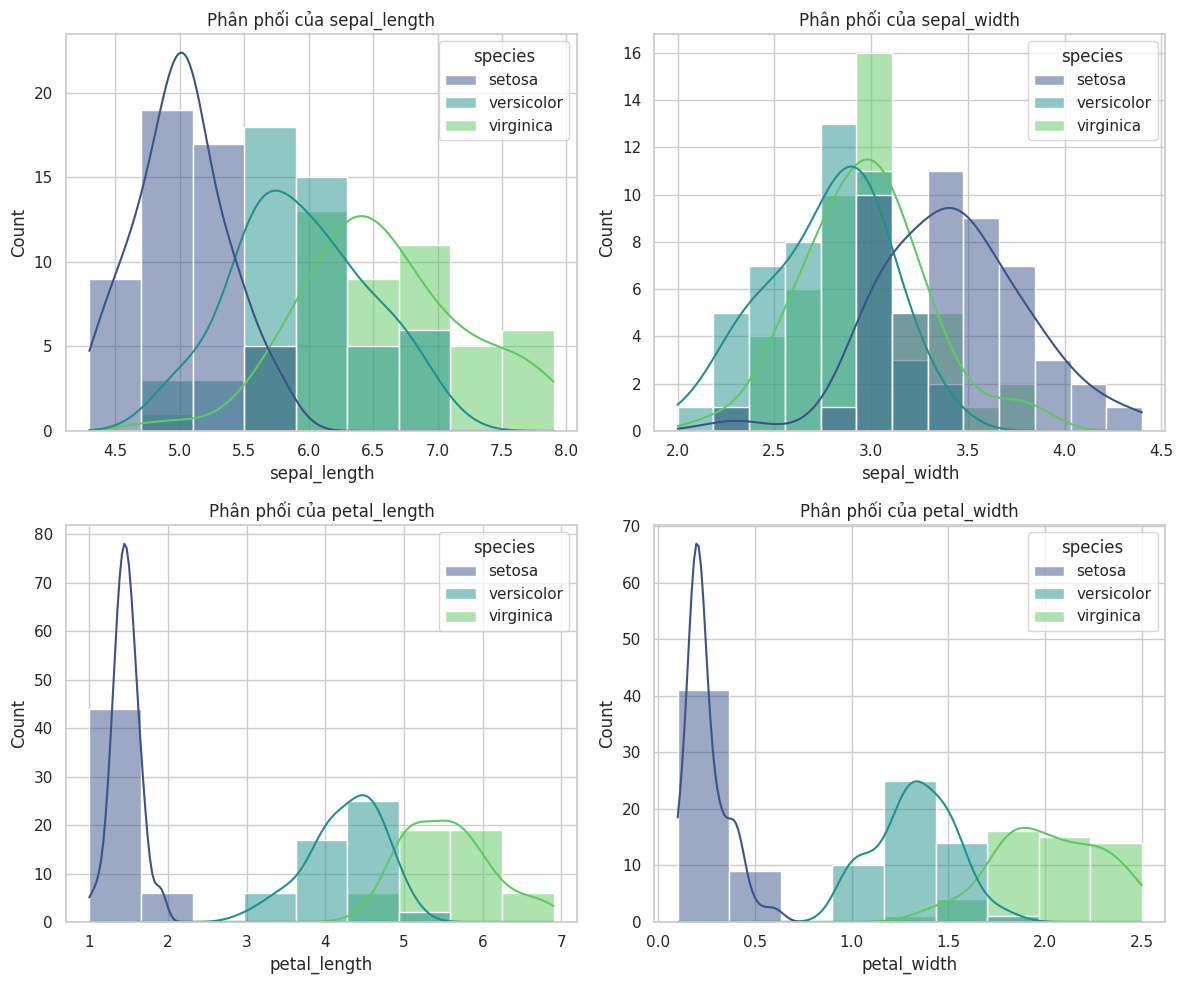

/tmp/ipykernel_1010/3418506396.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='species', y=feature, ax=ax, palette='Set2')
/tmp/ipykernel_1010/3418506396.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='species', y=feature, ax=ax, palette='Set2')
/tmp/ipykernel_1010/3418506396.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='species', y=feature, ax=ax, palette='Set2')
/tmp/ipykernel_1010/3418506396.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be remo

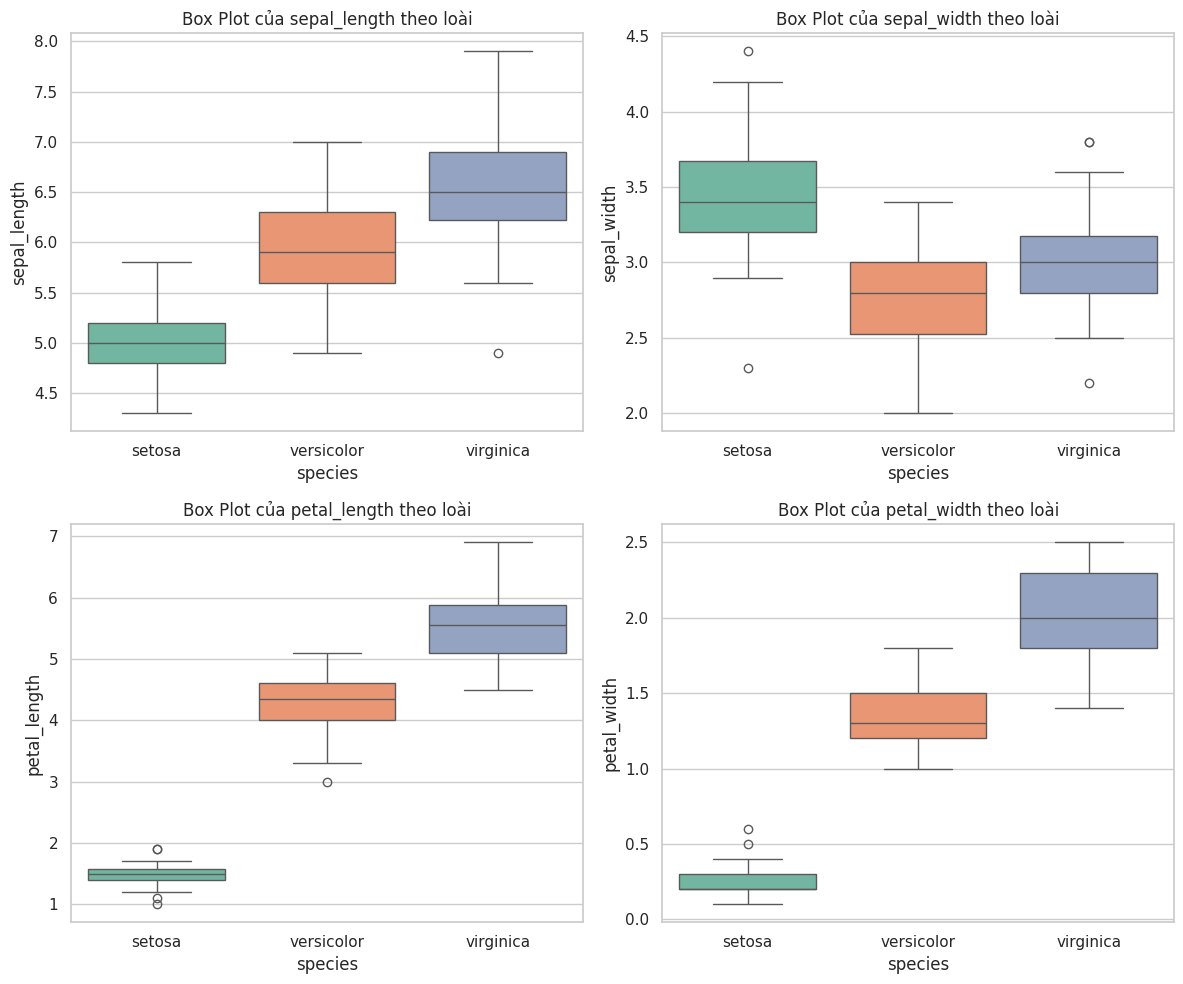

In [2]:
# Thiết lập style
sns.set_theme(style="whitegrid")

# 1. Histogram cho từng đặc trưng (phân tách theo loài để thấy rõ sự khác biệt)
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
features = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']

for i, feature in enumerate(features):
    ax = axes[i//2, i%2]
    sns.histplot(data=df, x=feature, hue='species', kde=True, ax=ax, palette='viridis')
    ax.set_title(f'Phân phối của {feature}')

plt.tight_layout()
plt.show()

# 2. Box Plot cho từng đặc trưng
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for i, feature in enumerate(features):
    ax = axes[i//2, i%2]
    sns.boxplot(data=df, x='species', y=feature, ax=ax, palette='Set2')
    ax.set_title(f'Box Plot của {feature} theo loài')

plt.tight_layout()
plt.show()

## Pairplot - Quan hệ giữa các đặc trưng

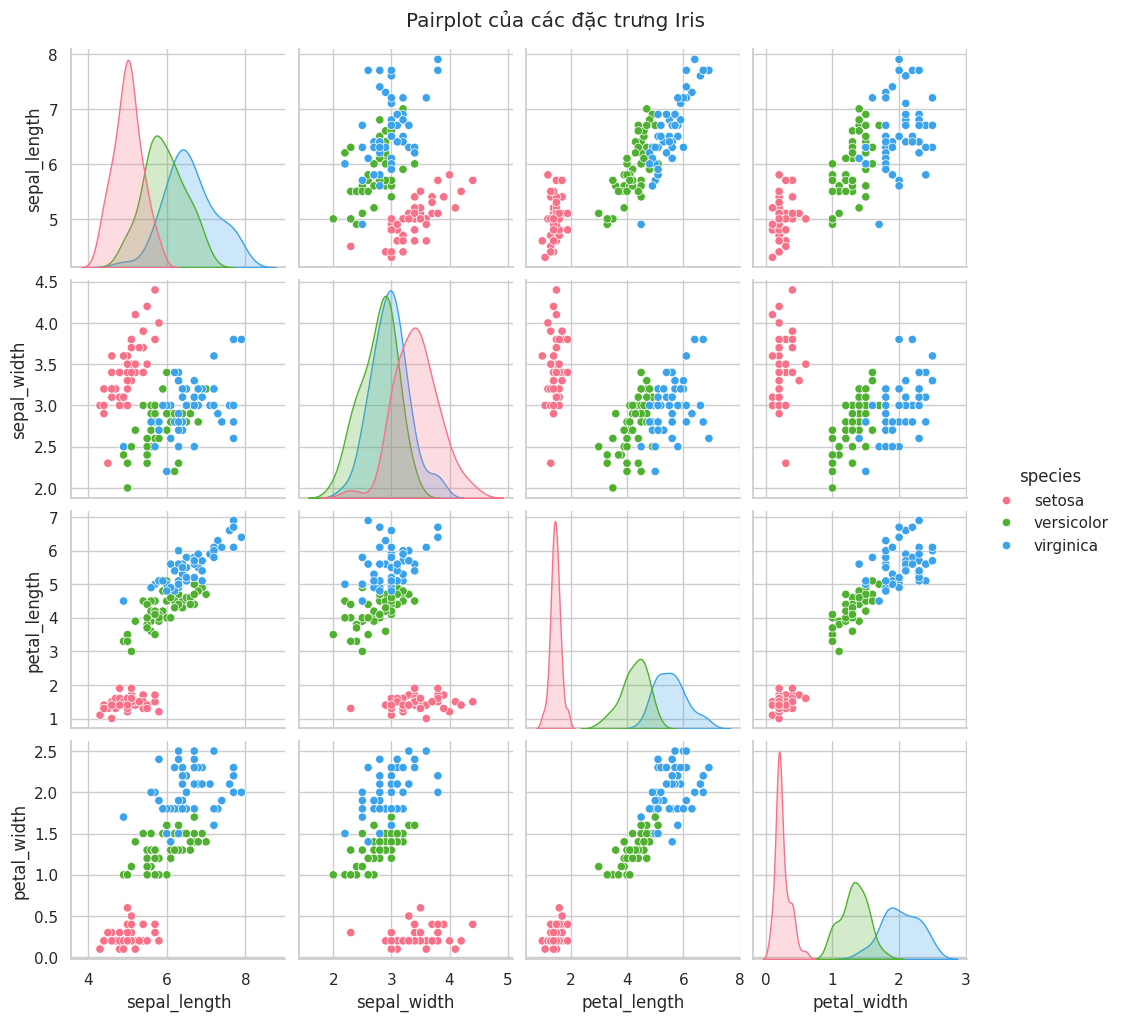

In [3]:
# Vẽ Pairplot với màu sắc theo loài
sns.pairplot(df, hue='species', diag_kind='kde', palette='husl')
plt.suptitle('Pairplot của các đặc trưng Iris', y=1.02)
plt.show()

## Ma trận Tương quan và Heatmap

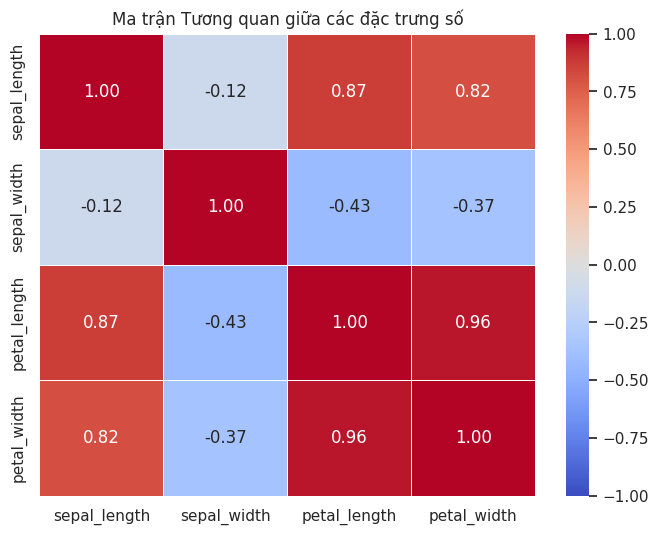

In [4]:
# Tính ma trận tương quan (bỏ cột species vì là biến phân loại)
corr_matrix = df.drop(columns='species').corr()

# Vẽ Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5, fmt='.2f')
plt.title('Ma trận Tương quan giữa các đặc trưng số')
plt.show()